# Personal Info

Name: Arshia Goshtasbi

# Librarires

In [1]:
import numpy as np
import random

from sklearn.datasets import fetch_california_housing

# Load Dataset

In [2]:
data = fetch_california_housing()
X = data.data
sample_numbers = 4000
indices = np.random.choice(X.shape[0], sample_numbers, replace=False)
x_data = X[indices]

# Implement KMeans algorithm (do not use any libraries and implement it from scratch)

In [3]:
class KMeans:
    def __init__(self, n_clusters=5, max_iter=1000):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.centroids = None
        self.labels_ = None
        
    def fit(self, X):
        # Initialize centroids randomly
        indices = np.random.choice(X.shape[0], self.n_clusters, replace=False)
        self.centroids = X[indices]
        
        for _ in range(self.max_iter):
            # Assign each point to the nearest centroid
            distances = np.sqrt(((X - self.centroids[:, np.newaxis])**2).sum(axis=2))
            self.labels_ = np.argmin(distances, axis=0)
            
            # Update centroids
            new_centroids = np.array([X[self.labels_ == i].mean(axis=0) for i in range(self.n_clusters)])
            
            # Check for convergence
            if np.allclose(new_centroids, self.centroids):
                break
                
            self.centroids = new_centroids
            
    def wcss(self, X):
        wcss = 0
        for i in range(self.n_clusters):
            cluster_points = X[self.labels_ == i]
            wcss += np.sum((cluster_points - self.centroids[i])**2)
        return wcss

# Use elbow method and silhouette method to choose optimal cluster numbers

In [4]:
def elbow_method(X, max_k=10):
    wcss_values = []
    for k in range(1, max_k+1):
        kmeans = KMeans(n_clusters=k)
        kmeans.fit(X)
        wcss_values.append(kmeans.wcss(X))
    return wcss_values

def silhouette_score(X, labels):
    n = len(X)
    s = np.zeros(n)
    for i in range(n):
        a_i = np.mean(np.sqrt(np.sum((X[i] - X[labels == labels[i]])**2, axis=1)))
        b_i = np.min([np.mean(np.sqrt(np.sum((X[i] - X[labels == k])**2, axis=1))) 
                      for k in set(labels) if k != labels[i]])
        s[i] = (b_i - a_i) / max(a_i, b_i)
    return np.mean(s)

def silhouette_method(X, max_k=10):
    silhouette_scores = []
    for k in range(2, max_k+1):
        kmeans = KMeans(n_clusters=k)
        kmeans.fit(X)
        score = silhouette_score(X, kmeans.labels_)
        silhouette_scores.append(score)
    return silhouette_scores

# Compare your k means algorithm with sklearn k means algorithm (compare it with both elbow and silhouette method)

In [5]:
from sklearn.cluster import KMeans as SKMeans
from sklearn.metrics import silhouette_score as sk_silhouette_score

# Elbow Method Comparison
custom_wcss = elbow_method(x_data)
sklearn_wcss = []
for k in range(1, 11):
    sklearn_kmeans = SKMeans(n_clusters=k, random_state=0).fit(x_data)
    sklearn_wcss.append(sklearn_kmeans.inertia_)

# Silhouette Method Comparison
custom_silhouette = silhouette_method(x_data)
sklearn_silhouette = []
for k in range(2, 11):
    sklearn_kmeans = SKMeans(n_clusters=k, random_state=0).fit(x_data)
    sklearn_silhouette.append(sk_silhouette_score(x_data, sklearn_kmeans.labels_))

### what is the optimal cluster number based on your custom kmeans algorithm and sklearn kmeans algorithm? if answer is different based on each algorithm then explain difference

### would you prefer elbow method for determining optimal cluster number or silhouette method?
#### I prefer silhouette method because in elbow method sometimes it's hard to say where is the elbow point but silhouette method is more deterministic rather than elbow method

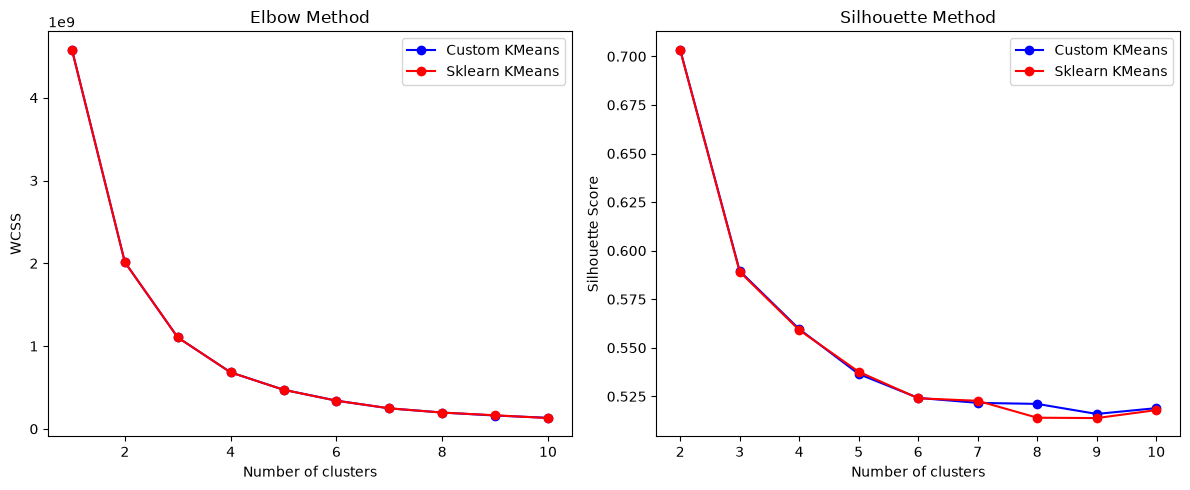

In [6]:
import matplotlib.pyplot as plt

# Plot Elbow Method
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(range(1, 11), custom_wcss, 'bo-', label='Custom KMeans')
plt.plot(range(1, 11), sklearn_wcss, 'ro-', label='Sklearn KMeans')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.legend()

# Plot Silhouette Method
plt.subplot(1, 2, 2)
plt.plot(range(2, 11), custom_silhouette, 'bo-', label='Custom KMeans')
plt.plot(range(2, 11), sklearn_silhouette, 'ro-', label='Sklearn KMeans')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Method')
plt.legend()
plt.tight_layout()
plt.show()